# EDA: корпус ИТМО для UniAssist · HW2

Снимок от 11 ноября 2026. Задача: справочные ответы о поступлении на бакалавриат.

**Выполнено:** сбор HTML, EDA и поисковый smoke-run. **Не выполнено:** чтение закрытых для обхода PDF, независимая разметка, closed test, генерация, маршрутизация, пилот.

Этот ноутбук воспроизводится из диагностических CSV в репозитории без сети и без полного исходного корпуса. Данные не являются случайной выборкой запросов пользователей. Подробные выводы: `reports/eda.md`.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
SNAPSHOT = "20261111_itmo_bachelor_reviewed_v2"
DATA = ROOT / "reports/data" / SNAPSHOT
docs = pd.read_csv(DATA / "documents.csv", keep_default_na=False)
chunks = pd.read_csv(DATA / "chunks.csv", keep_default_na=False)
failures = pd.read_csv(DATA / "failures.csv")
pairs = pd.read_csv(DATA / "near_duplicates.csv")
print("Python:", sys.version.split()[0], "pandas:", pd.__version__)
assert docs.url.is_unique
assert chunks.chunk_id.is_unique
assert not docs.raw_sha256.eq("").any()
print("Документы:", len(docs), "Окна:", len(chunks), "Пропуски:", len(failures))

Python: 3.11.15 pandas: 3.1.1
Документы: 44 Окна: 631 Пропуски: 15


## 1. Состав, объём и длины

59 кандидатов: 44 полученных HTML и 15 PDF, пропущенных до запроса из-за robots.txt. PDF нет в анализируемой выборке; качество PDF не измерялось.

{
  "snapshot": "20261111_itmo_bachelor_reviewed_v2",
  "documents": 44,
  "formats": {
    "html": 44
  },
  "bytes": 16981098,
  "words": 92892,
  "chars": 719463,
  "chunks": 631,
  "eligible_documents": 40,
  "eligible_chunks": 576,
  "pdf_pages": 0,
  "word_quantiles": {
    "0.0": 49.0,
    "0.25": 782.75,
    "0.5": 2414.5,
    "0.75": 2574.0,
    "0.95": 2889.05,
    "1.0": 13302.0
  },
  "topics": {
    "programs": 27,
    "exams": 2,
    "admission_rules": 2,
    "application": 2,
    "overview": 1,
    "contacts": 1,
    "faq": 1,
    "accessibility": 1,
    "dormitory": 1,
    "achievements": 1,
    "admission_places": 1,
    "minimum_scores": 1,
    "regulations": 1,
    "funding": 1,
    "target_quota": 1
  },
  "quality_flags": {
    "Без явного года кампании": 35,
    "Смешанные уровни образования": 6,
    "Повторные строки ≥ 10% текста": 29,
    "Мало текста (<80 слов)": 1,
    "Точные дубликаты документов": 0,
    "Страницы PDF с <50 символами": 0,
    "Есть публичные

,documents,words,bytes
format,,,
html,44,92892,16981098


,words,chars,bytes
count,44.0,44.0,44.0
mean,2111.2,16351.4,385934.0
std,1998.4,15875.1,417578.5
min,49.0,332.0,36628.0
25%,782.8,6580.0,223823.8
50%,2414.5,18237.0,253302.0
75%,2574.0,19434.8,325297.2
max,13302.0,106620.0,1655584.0


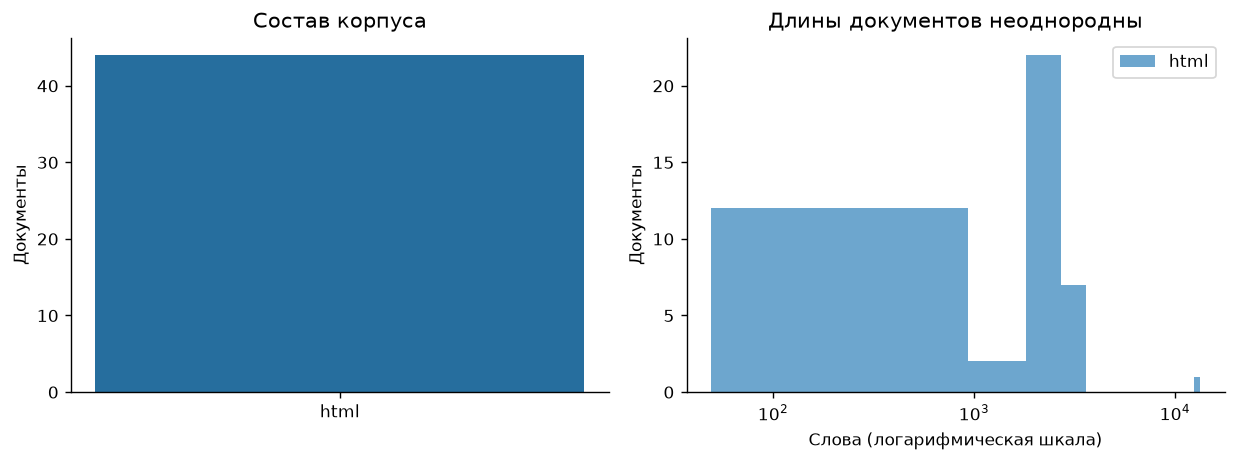

In [2]:
from scripts.run_eda import run

summary = run(SNAPSHOT)
display(
    docs.groupby("format").agg(
        documents=("url", "count"), words=("words", "sum"), bytes=("bytes", "sum")
    )
)
display(docs[["words", "chars", "bytes"]].describe().round(1))
display(Image(filename=str(ROOT / "reports/figures/01_composition.png")))

**Вывод.** Документы неоднородны: 49–13 302 слова, медиана 2 414,5. HTML-байты включают служебные данные и не равны полезному тексту. Число слов не равно числу токенов LLM. Нужны фрагменты с сохранением подтверждения и источника.

## 2. Тематический состав

Темы назначены по типам страниц в реестре, это не предсказание модели и не распределение пользовательского спроса.

,documents,words
topic,,
programs,27,68441
admission_rules,2,13705
application,2,791
exams,2,1799
accessibility,1,295
achievements,1,806
admission_places,1,49
contacts,1,713
dormitory,1,82


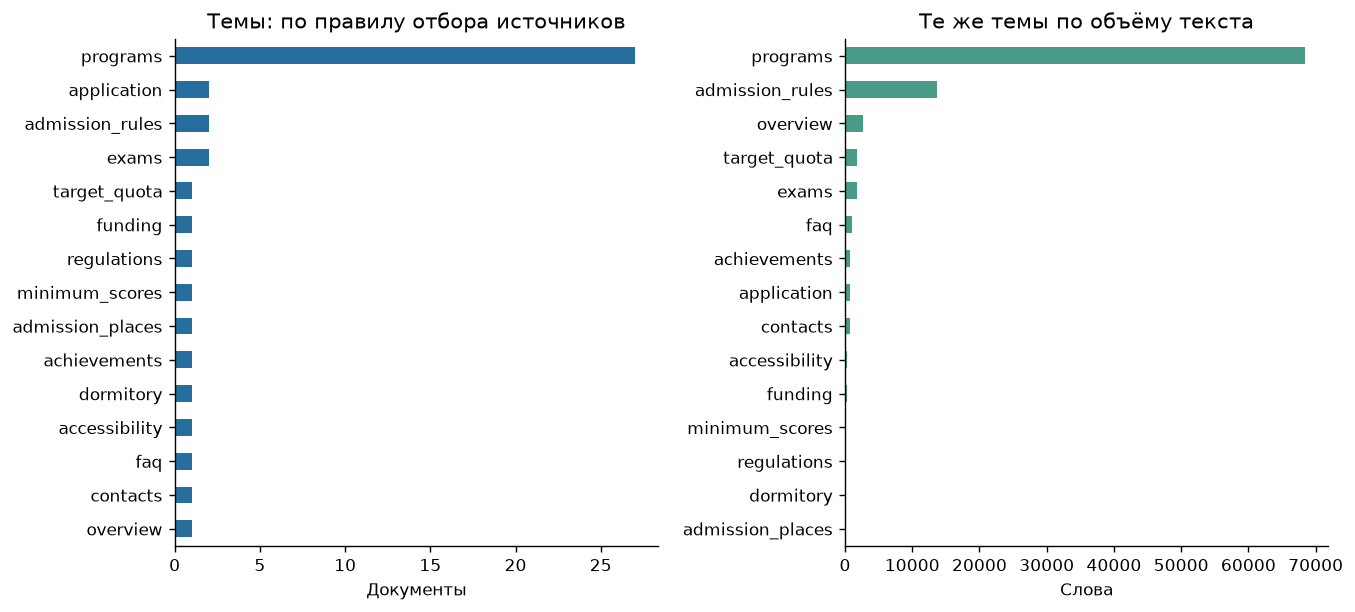

In [3]:
display(
    docs.groupby("topic")
    .agg(documents=("url", "count"), words=("words", "sum"))
    .sort_values("documents", ascending=False)
)
display(Image(filename=str(ROOT / "reports/figures/02_topics.png")))

**Вывод.** 27 из 44 страниц — паспорта программ; нормативные правила занимают большой объём при малом числе URL. Для будущей оценки нужны квоты вопросов о сроках, документах, достижениях и случаях без ответа. Усреднение по страницам не измеряет полезность пользователю.

## 3. Актуальность и границы действия

`year_mentions` — любые годы в тексте. `campaign_year` — отдельная предварительная разметка. `fetched_at` — дата получения. Их нельзя подменять друг другом.

,documents
freshness,
explicit_2026,9
mixed_campaign,3
undated,32


,url,freshness,raw_sha256
17,https://abit.itmo.ru/program/bachelor/ai,mixed_campaign,b54f4b9fd426c6b63d14ff912cb6a9d8a57457cc2493c0...
37,https://abit.itmo.ru/program/bachelor/programming,mixed_campaign,184736ce0f2f5296776531be8d87b08fcbaf372ee79864...
39,https://abit.itmo.ru/program/bachelor/software...,mixed_campaign,f06566f07e89b341d79e4ed3cdc1d0b0067d2a0e6fdeb9...


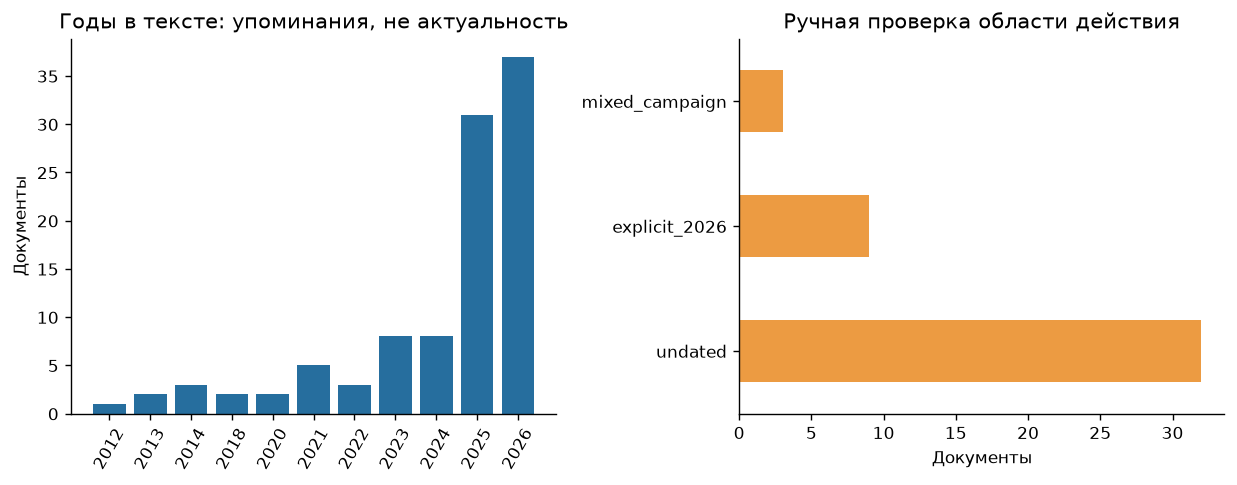

In [4]:
display(docs.groupby("freshness").size().rename("documents").to_frame())
display(docs[docs.freshness.eq("mixed_campaign")][["url", "freshness", "raw_sha256"]])
display(Image(filename=str(ROOT / "reports/figures/03_freshness.png")))

**Наблюдение.** В трёх паспортах сохранены даты начала приёма за 2025 год; детали привязаны к хешам в `data/sources/review.csv`. Они исключены из поискового эксперимента до разметки секций.

**Вывод.** Упоминание исторического года в дипломе олимпиады не делает документ устаревшим. Но старый дедлайн в секции дат нельзя автоматически применять к новой кампании. Нужна проверка критических фактов по утверждённой редакции. Корпус 2026 не доказывает правила 2027.

## 4. Качество, таблицы и смешение уровней

,url,words,education_level,freshness,retrieval_eligible
0,https://abit.itmo.ru/bachelor,2617,mixed,explicit_2026,True
2,https://abit.itmo.ru/faq,1100,mixed,explicit_2026,True
4,https://abit.itmo.ru/page/113,403,mixed,explicit_2026,True
9,https://abit.itmo.ru/page/71,49,bachelor,explicit_2026,False
11,https://abit.itmo.ru/page/74,1679,mixed,undated,True
12,https://abit.itmo.ru/page/80,179,mixed,explicit_2026,True
13,https://abit.itmo.ru/page/86,308,mixed,explicit_2026,True
17,https://abit.itmo.ru/program/bachelor/ai,2095,bachelor,mixed_campaign,False
37,https://abit.itmo.ru/program/bachelor/programming,2987,bachelor,mixed_campaign,False
39,https://abit.itmo.ru/program/bachelor/software...,2903,bachelor,mixed_campaign,False


,url,error
0,https://abit.itmo.ru/file_storage/file/pages/8...,ValueError: robots.txt disallows https://abit....
1,https://abit.itmo.ru/file_storage/file/pages/8...,ValueError: robots.txt disallows https://abit....
2,https://abit.itmo.ru/file_storage/file/pages/8...,ValueError: robots.txt disallows https://abit....


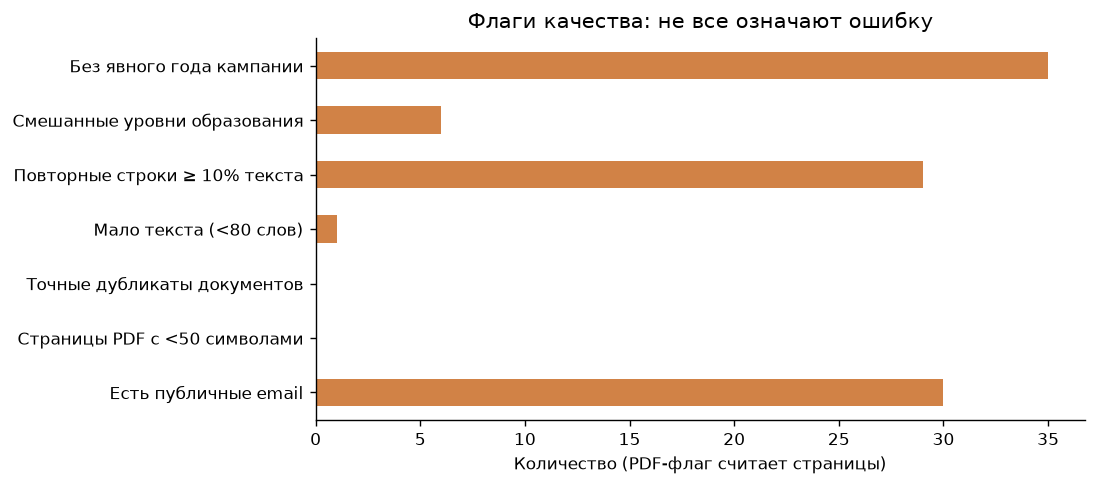

In [5]:
flags = docs[docs.low_text | docs.education_level.eq("mixed") | docs.freshness.eq("mixed_campaign")]
display(flags[["url", "words", "education_level", "freshness", "retrieval_eligible"]])
display(failures[["url", "error"]].head(3))
display(Image(filename=str(ROOT / "reports/figures/04_quality.png")))

**Вывод.** `/page/71` содержит заголовки без значений мест; исключён по малому тексту. В шести документах отмечены смешанные уровни образования. HTTP 200, достаточная длина и официальный домен не гарантируют корректный контекст для ответа. Порог 80 слов не обнаруживает все проблемы. Нулевой флаг пустых PDF-страниц объясняется отсутствием PDF, а не хорошим OCR.

Email найдены в 30 документах. Это публичные контакты, но корпус не следует считать свободным от персональных данных. В CSV хранятся только счётчики, не извлечённые значения.

## 5. Повторы внутри страниц и сходство документов

Точные дубликаты: 0
Кандидаты пар Jaccard >= .35: 296


,left_url,right_url,jaccard_5gram
190,https://abit.itmo.ru/program/bachelor/gamedesign,https://abit.itmo.ru/program/bachelor/gamedev,0.7644
285,https://abit.itmo.ru/program/bachelor/programming,https://abit.itmo.ru/program/bachelor/software...,0.7519
276,https://abit.itmo.ru/program/bachelor/neurotec...,https://abit.itmo.ru/program/bachelor/system_s...,0.7090
155,https://abit.itmo.ru/program/bachelor/design,https://abit.itmo.ru/program/bachelor/system_s...,0.6972
281,https://abit.itmo.ru/program/bachelor/photonics,https://abit.itmo.ru/program/bachelor/system_s...,0.6889
274,https://abit.itmo.ru/program/bachelor/neurotec...,https://abit.itmo.ru/program/bachelor/photonics,0.6851
79,https://abit.itmo.ru/program/bachelor/biotechn...,https://abit.itmo.ru/program/bachelor/photonics,0.6739
202,https://abit.itmo.ru/program/bachelor/gamedesign,https://abit.itmo.ru/program/bachelor/urbanistics,0.6632


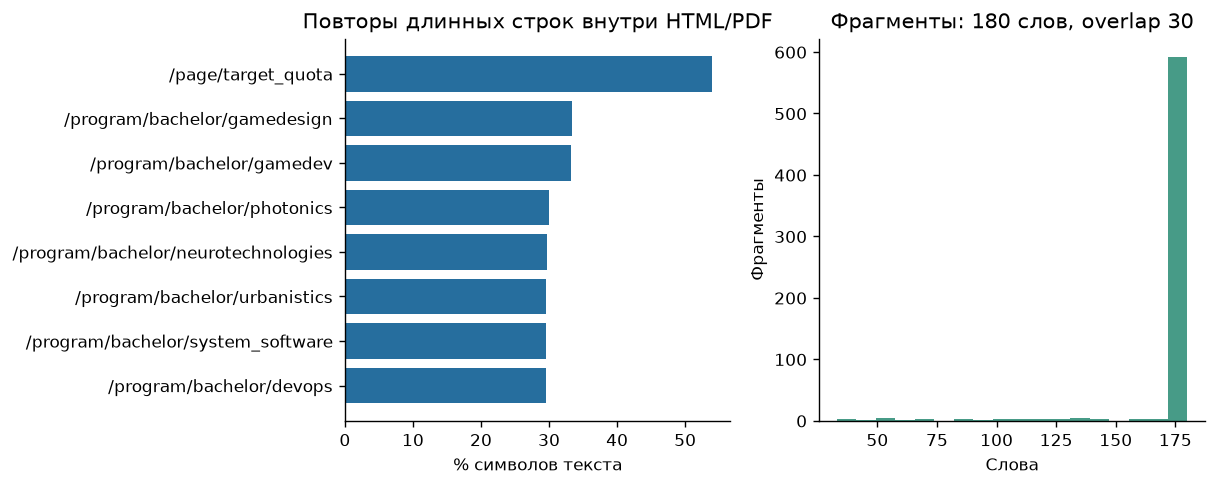

In [6]:
print("Точные дубликаты:", docs.exact_duplicate_of.ne("").sum())
print("Кандидаты пар Jaccard >= .35:", len(pairs))
display(pairs.sort_values("jaccard_5gram", ascending=False).head(8))
display(Image(filename=str(ROOT / "reports/figures/05_repetition_chunks.png")))

**Вывод.** 29 документов имеют не менее 10% символов повторных длинных строк. 296 пар по 5-граммам — кандидаты общих шаблонов, а не основание удалить 296 документов. У разных программ могут совпадать общие правила, но различаться стоимость и условия. Числовые повторы таблиц удалять нельзя. Следующий вариант — канонические общие блоки и сохранение уникальных полей.

## 6. Размер фрагмента

,size_words,overlap_words,chunks
0,100,20,1172
1,180,30,631
2,300,50,385


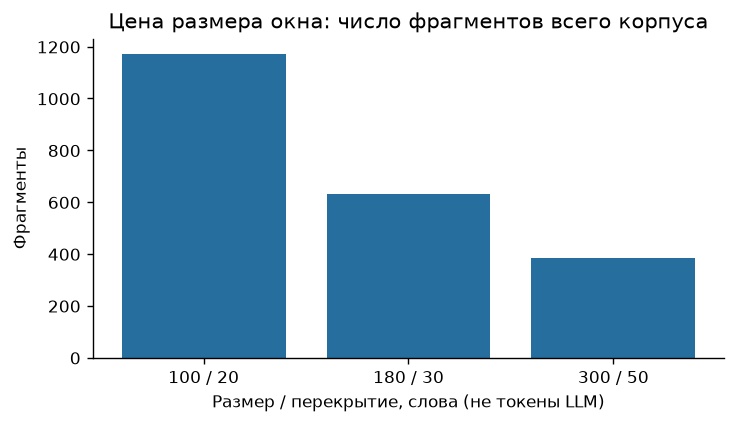

Допущено документов: 40
Допущено фрагментов: 576


In [7]:
display(pd.read_csv(DATA / "chunking_comparison.csv"))
display(Image(filename=str(ROOT / "reports/figures/06_chunking_tradeoff.png")))
print("Допущено документов:", int(docs.retrieval_eligible.sum()))
print("Допущено фрагментов:", int(chunks.retrieval_eligible.sum()))

**Вывод.** Окна 100/20 дают 1 172 фрагмента, 180/30 — 631, 300/50 — 385. Размер 180/30 выбран как фиксированный старт, не оптимизировался на вопросах. Окно может разорвать пару FAQ или строку таблицы; структурный чанкинг — проверяемая гипотеза следующей итерации.

## 7. Открытая проверка BM25

In [8]:
baseline = json.loads((ROOT / "reports/baseline/bm25_dev_v2/summary.json").read_text())
print(
    json.dumps(
        {
            k: baseline[k]
            for k in [
                "split",
                "answerable_questions",
                "policy_cases_not_evaluated",
                "source_hit_at_5",
                "evidence_hit_at_5",
                "evidence_mrr_at_10",
            ]
        },
        ensure_ascii=False,
        indent=2,
    )
)
per_question = pd.read_csv(ROOT / "reports/baseline/bm25_dev_v2/per_question.csv")
display(
    per_question.groupby("topic").agg(
        n=("question_id", "count"), evidence_hit=("evidence_hit_at_5", "mean")
    )
)
assert len(per_question) == 24
assert baseline["index_chunks"] == int(chunks.retrieval_eligible.sum())

{
  "split": "development",
  "answerable_questions": 24,
  "policy_cases_not_evaluated": 12,
  "source_hit_at_5": 0.6666666666666666,
  "evidence_hit_at_5": 0.5,
  "evidence_mrr_at_10": 0.3810185185185186
}


,n,evidence_hit
topic,,
achievements,2,0.0
appeals,1,1.0
application,8,0.5
contacts,1,1.0
deadlines,1,1.0
dormitory,1,1.0
format,1,0.0
medical,1,1.0
olympiads,2,0.5


**Вывод.** На 24 модельных вопросах разработки известное подтверждение найдено в top-5 в 12 случаях. Более частое попадание в правильную страницу ещё не означает нахождение ответа. Это Hit по одному известному span, не Recall по исчерпывающей разметке. Альтернативное корректное подтверждение может отсутствовать в qrels.

12 сценариев отказа/уточнения/эскалации не оценивались: соответствующий модуль не реализован. Качество генерации, precision ответов, реальный спрос и бизнес-эффект неизвестны. Следующие шаги: независимая разметка, структура секций и таблиц, устранение шаблонной конкуренции, затем сравнение retrieval при одинаковых данных.